# 02 — Comparación A (features MQTT) vs B (solo TCP)

Segundo notebook de tres. Compara de forma controlada:

- **A**: 13 features con campos MQTT en claro (`data_preprocessing/mqtt_features.py`).
- **B**: 12 features TCP/IP causales (`data_preprocessing/tcp_features.py`),
  observables también con MQTTS.

Ambos sets usan **los mismos folds, el mismo XGBoost de hiperparámetros fijos y el
mismo `sample_weight` balanceado** (`evaluation/`). No se entrena el modelo final ni
se exporta nada: eso es `03_modelo_tcp.ipynb`, que también contiene las ablaciones
de B.

**Entrada:** `ML_Model/artifacts/df_raw.joblib` del notebook 01. Aquí no se vuelve a
limpiar el dataset.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

SEED = 42


def find_repo_root(start=None):
    """Sube desde el cwd hasta la carpeta que contiene `dataset/` y `ML_Model/`."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'dataset').is_dir() and (candidate / 'ML_Model').is_dir():
            return candidate
    raise FileNotFoundError(f'No se encontró la raíz del repositorio desde {start}')


REPO_ROOT = find_repo_root()
MODEL_CODE_DIR = REPO_ROOT / 'ML_Model'
if str(MODEL_CODE_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_CODE_DIR))

# Re-ejecutar en el mismo kernel recarga los paquetes locales.
for name in [m for m in sys.modules if m.split('.')[0] in ('data_preprocessing', 'evaluation')]:
    del sys.modules[name]

from data_preprocessing.artifacts import load_clean_artifact
from data_preprocessing.feature_engineering import FEATURE_COLUMNS
from data_preprocessing.load_data import TARGET_COL
from data_preprocessing.mqtt_features import build_feature_matrix
from data_preprocessing.tcp_features import TCP_FEATURE_COLUMNS, build_tcp_features
import evaluation as ev

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

## 1. Cargar el artefacto del notebook 01

`load_clean_artifact` verifica el SHA-256 contra `manifest.json`; si no coincide hay
que reejecutar `01_eda_politica.ipynb`. La estrategia de split también viene del
manifiesto (decisión 2.3.4 del notebook 01).

In [2]:
df_raw, manifest = load_clean_artifact(MODEL_CODE_DIR / 'artifacts')
NEEDS_LOCO = manifest['split_strategy'] != 'StratifiedGroupKFold por _connection'
print(f"df_raw: {df_raw.shape}  generado {manifest['generated_at']}")
print('Split:', manifest['split_strategy'],
      f"(normal concurrente = {manifest['normal_concurrent_share_dos']:.1%})")
display(pd.DataFrame(manifest['counts_by_capture_and_class']).T)

df_raw: (257457, 21)  generado 2026-10-22T16:50:45+00:00
Split: StratifiedGroupKFold por _connection (normal concurrente = 58.6%)


,normal,DoS
DoS,43000,45460
Intrusion,69863,0
MitM,99134,0


## 2. Vista `mqtt`: frames con puerto 1883/8883

La comparación principal se hace solo con frames que tienen puerto 1883 u 8883 en
origen o destino. Se filtra por puerto, no por capa MQTT, para conservar los SYN/ACK
de las conexiones MQTT (que el agente también ve) y los frames DoS sin capa MQTT.
Así se elimina el atajo "normal no-MQTT vs DoS MQTT" visto en el notebook 01.

In [3]:
df_scope = ev.mqtt_scope(df_raw)
scope_frames, scope_connections = ev.scope_overview(df_scope)
print(f'df_scope: {df_scope.shape}')
display(scope_frames)
display(scope_connections)

df_scope: (61654, 21)


type,DoS,normal,total
_capture,,,
DoS,45330,969,46299
Intrusion,0,7700,7700
MitM,0,7655,7655
total,45330,16324,61654


type,DoS,normal
_capture,,
DoS,886,41
Intrusion,0,368
MitM,0,23
total,886,432


## 3. Matrices A y B

Las dos se construyen sobre exactamente los mismos frames. Los puertos solo
alimentan las banderas `fe_is_*`; IP, puertos crudos y `frame.time_epoch` son claves
de agrupación/orden, nunca features.

In [4]:
X_scope_a = build_feature_matrix(df_scope)
X_scope_b = build_tcp_features(df_scope)
assert list(X_scope_a.columns) == FEATURE_COLUMNS
assert list(X_scope_b.columns) == TCP_FEATURE_COLUMNS
assert X_scope_a.index.equals(X_scope_b.index)
assert np.isfinite(X_scope_a.to_numpy()).all() and np.isfinite(X_scope_b.to_numpy()).all()

display(pd.DataFrame({
    'A (MQTT)': pd.Series(FEATURE_COLUMNS),
    'B (TCP)': pd.Series(TCP_FEATURE_COLUMNS),
}).fillna(''))

,A (MQTT),B (TCP)
0,frame.len,frame.len
1,frame.time_delta,fe_log_len
2,fe_bytes_per_sec,frame.time_delta
3,fe_is_standard_mqtt_port,fe_is_standard_mqtt_port
4,fe_is_broker_to_client,fe_is_broker_to_client
5,fe_log_len,tcp_iat
6,mqtt.hdrflags,tcp_iat_std_5s
7,mqtt.len,tcp_frames_5s
8,mqtt.topic_len,tcp_bytes_5s
9,fe_msg_entropy,tcp_len_std_5s


## 4. Folds y línea base

**Folds.** `StratifiedGroupKFold` por `_connection`: se intentan 5 y se reduce si algún
fold no tiene ambas clases o normal de las tres capturas.

**Línea base.** La mejor regla trivial dentro de la vista `mqtt`. Un set que no la
supere no aporta nada sobre "es MQTT ⇒ DoS".

In [5]:
scope_labels = ev.binary_labels(df_scope)
scope_groups = pd.factorize(df_scope['_connection'], sort=False)[0]
scope_captures = df_scope['_capture'].to_numpy()
scope_mqtt_layer = df_scope['mqtt.hdrflags'].notna().to_numpy()  # solo para el padding TLS

SCOPE_N_SPLITS, SCOPE_SPLITS = ev.find_grouped_splits(
    scope_labels, scope_groups, scope_captures,
    required_normal_captures=set(df_scope.loc[scope_labels == 0, '_capture']),
    max_splits=5, seed=SEED)
print(f'Folds: {SCOPE_N_SPLITS}')
display(ev.fold_composition(scope_labels, scope_captures, SCOPE_SPLITS))

scope_baseline = ev.trivial_rule_table(df_scope, scope_labels)
BASELINE_NAME, BASELINE_F1 = scope_baseline.index[0], float(scope_baseline['macro_f1'].iloc[0])
display(scope_baseline.round(4))
print(f'Línea base: {BASELINE_NAME} (macro-F1 = {BASELINE_F1:.4f})')

Folds: 5


,train,test,DoS_test,normal_test_DoS,normal_test_Intrusion,normal_test_MitM
fold,,,,,,
0,49320,12334,9070,234,840,2190
1,49324,12330,9065,93,3052,120
2,49324,12330,9065,221,1121,1923
3,49323,12331,9065,337,2093,836
4,49325,12329,9065,84,594,2586


,macro_f1,balanced_accuracy,dos_recall,dos_precision
regla,,,,
capa MQTT,0.6911,0.6849,0.8613,0.8295
cliente -> broker,0.6790,0.6648,0.8993,0.8142
cliente -> broker o capa MQTT,0.6025,0.5950,0.9063,0.7784
siempre DoS,0.4237,0.5000,1.0000,0.7352
broker -> cliente,0.2203,0.3352,0.1007,0.3938
siempre normal,0.2093,0.5000,0.0000,0.0000


Línea base: capa MQTT (macro-F1 = 0.6911)


## 5. Comparación A vs B

XGBoost con hiperparámetros fijos (`evaluation.XGB_PARAMS`), iguales para A y B.
Métricas por fold: macro-F1, balanced accuracy, ROC-AUC, recall/precisión de DoS,
recall del normal y tasa de falsos positivos por captura de origen del normal.

Hiperparámetros: {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 2.0, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_lambda': 1.0, 'objective': 'binary:logistic', 'tree_method': 'hist', 'eval_metric': 'logloss', 'n_jobs': -1}


,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,roc_auc_mean,roc_auc_std,dos_recall_mean,dos_recall_std,dos_precision_mean,dos_precision_std,normal_recall_mean,normal_recall_std,fp_DoS_mean,fp_DoS_std,fp_Intrusion_mean,fp_Intrusion_std,fp_MitM_mean,fp_MitM_std
set,,,,,,,,,,,,,,,,,,
A,0.9778,0.0027,0.9836,0.0020,0.9987,0.0002,0.9813,0.0028,0.9948,0.0010,0.9858,0.0028,0.0881,0.0414,0.0114,0.0058,0.0107,0.0064
B,0.9962,0.0010,0.9969,0.0009,0.9999,0.0000,0.9972,0.0008,0.9987,0.0005,0.9965,0.0014,0.0344,0.0236,0.0011,0.0011,0.0023,0.0028


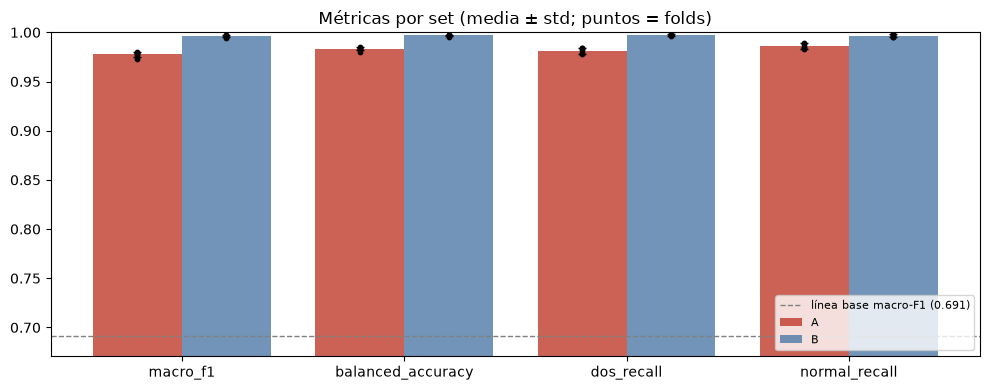

In [6]:
print('Hiperparámetros:', ev.XGB_PARAMS)
scope_folds, scope_importances = ev.compare_feature_sets(
    {'A': X_scope_a, 'B': X_scope_b}, scope_labels, scope_captures, SCOPE_SPLITS, seed=SEED)
scope_summary, scope_means = ev.summarize_folds(scope_folds)
display(scope_summary.round(4))
ev.plot_fold_metrics(scope_folds, baseline_f1=BASELINE_F1)

### 5.1 Falsos positivos por captura de origen

B no debe aumentar los FP en ninguna captura. El normal de `DoS.csv` es el más difícil:
convive en el tiempo con el ataque y en la vista `mqtt` tiene pocos frames.

,fp_DoS,fp_Intrusion,fp_MitM
set,,,
A,0.0881,0.0114,0.0107
B,0.0344,0.0011,0.0023


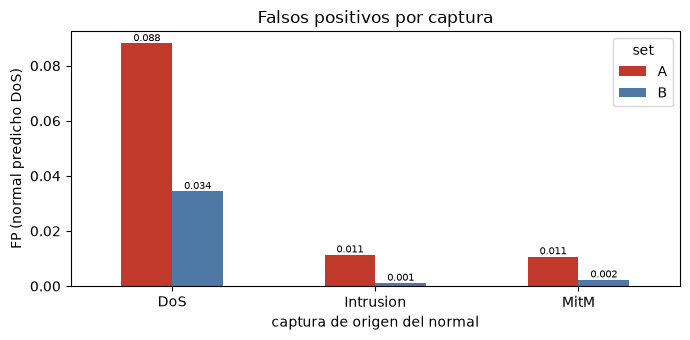

In [7]:
display(scope_means.filter(like='fp_').round(4))
ev.plot_fp_by_capture(scope_means)

### 5.2 Importancia de features

Peso medio de cada feature en los 5 modelos. Una feature con más del 50 % del peso
indica que el set depende de una sola señal.

,A,B
tcp_new_conns_5s,NaN,0.5445
frame.len,0.2796,0.2224
tcp_len_std_5s,NaN,0.0962
tcp_bytes_5s,NaN,0.0363
fe_log_len,0.1676,0.0220
frame.time_delta,0.0487,0.0214
tcp_asymmetry_5s,NaN,0.0206
tcp_iat_std_5s,NaN,0.0124
tcp_iat,NaN,0.0094
fe_is_broker_to_client,0.0186,0.0090


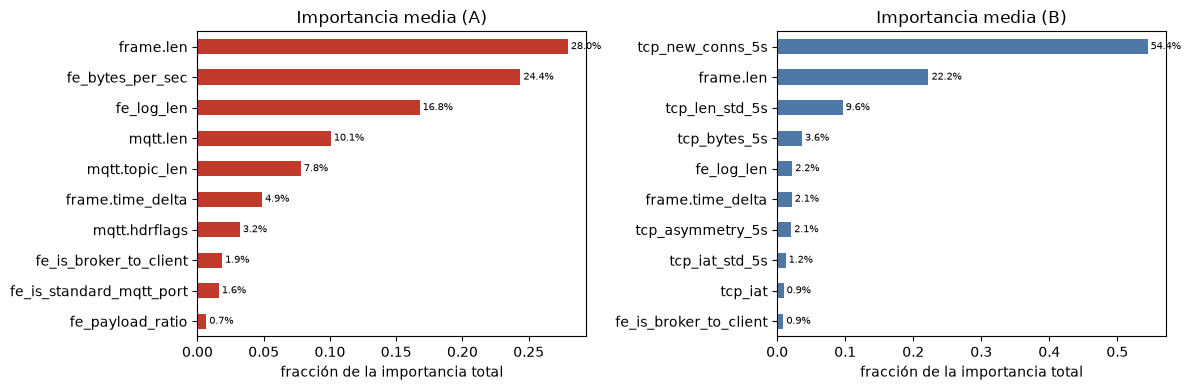

In [8]:
scope_importance = ev.mean_importance(scope_importances)
display((scope_importance / scope_importance.sum()).round(4)
        .sort_values('B', ascending=False))
ev.plot_importance(scope_importance, top=10)

## 6. Sensibilidad TLS aproximada (B)

Con MQTTS cada registro TLS añade ~21–40 bytes. Se suma ese padding a `frame.len` (y
se recalcula `fe_log_len`) solo en los frames MQTT de test, sin reentrenar. Es una
aproximación optimista: no recalcula las ventanas TCP que dependen de bytes ni
cambia los tiempos.

,macro_f1_base,macro_f1_tls,caida,frames_mqtt_perturbados
fold,,,,
0,0.9946,0.9934,0.0011,9045
1,0.9966,0.9966,-0.0000,9454
2,0.9957,0.9958,-0.0001,9473
3,0.9971,0.9960,0.0010,9613
4,0.9970,0.9935,0.0035,9484


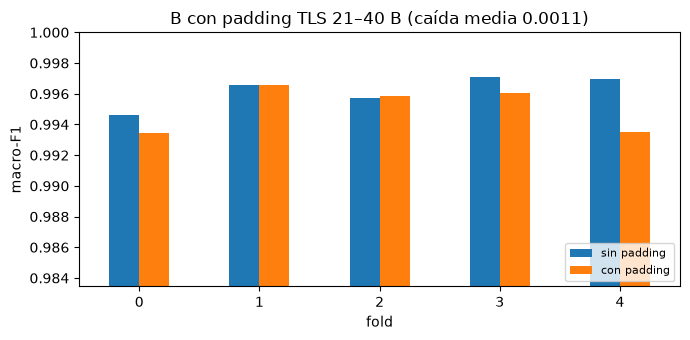

In [9]:
tls_sensitivity = ev.tls_padding_sensitivity(
    X_scope_b, scope_labels, SCOPE_SPLITS, scope_mqtt_layer, seed=SEED)
display(tls_sensitivity.round(4))
ev.plot_tls_sensitivity(tls_sensitivity)

## 7. Diagnóstico sobre todo el tráfico

Mismo protocolo sobre `df_raw` completo (sin filtro de puerto), solo como diagnóstico.
Si A rinde mucho mejor aquí que en la vista `mqtt`, parte de su ventaja venía de
separar "normal no-MQTT" de "DoS MQTT".

Folds sobre todo el tráfico: 5


,macro_f1,balanced_accuracy,dos_recall,dos_precision
regla,,,,
cliente -> broker,0.9101,0.9264,0.8968,0.8142
capa MQTT,0.9049,0.9105,0.8589,0.8295
cliente -> broker o capa MQTT,0.8989,0.9243,0.9037,0.7784
broker -> cliente,0.5277,0.5336,0.1004,0.3938
siempre normal,0.4516,0.5000,0.0000,0.0000
siempre DoS,0.1501,0.5000,1.0000,0.1766


,macro_f1,balanced_accuracy,roc_auc,dos_recall,dos_precision,normal_recall,fp_DoS,fp_Intrusion,fp_MitM
set,,,,,,,,,
A,0.9915,0.9950,0.9993,0.9949,0.9774,0.9950,0.0043,0.0064,0.0046
B,0.9981,0.9984,0.9999,0.9976,0.9963,0.9992,0.0022,0.0006,0.0005


set,A,B
vista mqtt,0.9778,0.9962
todo el tráfico,0.9915,0.9981


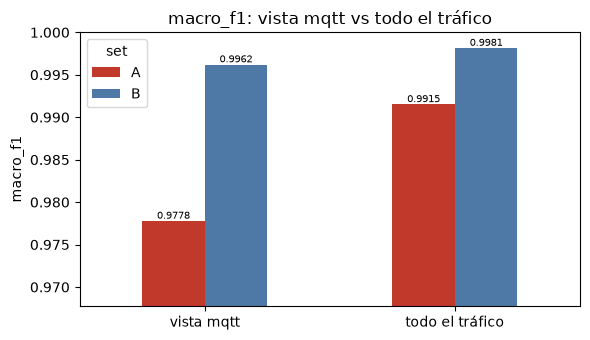

In [10]:
full_labels = ev.binary_labels(df_raw)
full_groups = pd.factorize(df_raw['_connection'], sort=False)[0]
full_captures = df_raw['_capture'].to_numpy()
X_full_a = build_feature_matrix(df_raw)
X_full_b = build_tcp_features(df_raw)

FULL_N_SPLITS, FULL_SPLITS = ev.find_grouped_splits(
    full_labels, full_groups, full_captures,
    required_normal_captures=set(df_raw.loc[full_labels == 0, '_capture']),
    max_splits=5, seed=SEED)
print(f'Folds sobre todo el tráfico: {FULL_N_SPLITS}')
full_baseline = ev.trivial_rule_table(df_raw, full_labels)
display(full_baseline.round(4))

full_folds, _ = ev.compare_feature_sets(
    {'A': X_full_a, 'B': X_full_b}, full_labels, full_captures, FULL_SPLITS, seed=SEED)
_, full_means = ev.summarize_folds(full_folds)
display(full_means.round(4))

views = pd.DataFrame({'vista mqtt': scope_means['macro_f1'],
                      'todo el tráfico': full_means['macro_f1']}).T
display(views.round(4))
ev.plot_scope_vs_full(views)

## 8. Decisión

Criterio del plan: **B** si su macro-F1 queda a ≤ 0,03 de A, supera la línea base y no
aumenta los FP en ninguna captura de origen; **A** en caso contrario, documentando que
solo vale para MQTT en claro. El peso de la feature dominante es un aviso, no bloquea.

In [11]:
checks, DECISION = ev.decide_a_vs_b(scope_means, BASELINE_F1, scope_importance['B'])
display(checks)
print(f'DECISIÓN: {DECISION}')

if NEEDS_LOCO:
    print('Leave-one-capture-out del normal (exigido por el notebook 01):')
    display(ev.leave_one_capture_out({'A': X_scope_a, 'B': X_scope_b},
                                     scope_labels, scope_captures, seed=SEED).round(4))
else:
    print('Leave-one-capture-out no requerido: el normal convive con el ataque (notebook 01).')

,valor,cumple
criterio,,
macro-F1 de B a ≤ 0.03 de A,A-B = -0.0184,True
B supera la línea base,0.9962 vs 0.6911,True
B no aumenta FP en ninguna captura,ninguna empeora,True
"ninguna feature de B pesa > 50% (aviso, no bloquea)",tcp_new_conns_5s = 54.4%,False


DECISIÓN: B
Leave-one-capture-out no requerido: el normal convive con el ataque (notebook 01).


## 9. Conclusión

**Se elige B (solo TCP) como set final.** En la vista `mqtt`, B supera a A en macro-F1
(≈ 0,996 vs ≈ 0,978), supera ampliamente la mejor regla trivial ("capa MQTT ⇒ DoS",
≈ 0,69) y reduce los falsos positivos en las tres capturas de origen del normal. El
padding TLS aproximado apenas lo afecta (caída media ≈ 0,001).

Razones:

- **Semántica.** B solo usa comportamiento de red/transporte, observable también con
  MQTTS. A depende de campos `mqtt.*` que con TLS no existen.
- **Estadística.** El dataset asocia "es MQTT" con "es DoS". A aprovecha ese atajo; en
  todo el tráfico rinde mejor que en la vista `mqtt`, donde el atajo desaparece.

Límites que pasan al notebook 03:

- B depende mucho de `tcp_new_conns_5s` (> 50 % de la importancia): el único DoS
  grabado es un flood de conexiones nuevas. Las ablaciones de B (sin esa feature y sin
  `tcp_asymmetry_5s`) están en `03_modelo_tcp.ipynb`.
- Solo hay una captura DoS; las métricas valen para ese escenario. Falta validar en
  caliente con el simulador (conexiones persistentes, otras tasas y TLS en 8883).